# Lab 10 — Odometry vs gyro localization ("47")

Same program and controller (turn in place, then drive) in both runs; only the course changes:
**run A** (`lab10_runA.qrs`, MODE 0): `course = course_odom` · **run B** (`lab10_runB.qrs`, MODE 1): `course = course + gyro_inc`, with $s$ = −6.2 % from Lab 9 and $b_0$ measured in the first 10 s.
Log columns: `t, theta_l, theta_r, gz, i, x, y, course, course_odom, course_gyro` (ms, rad, rad, mdeg/s, waypoint, cm, cm, rad, rad, rad); rows with `i = 0` are the 10 s at rest.

In [1]:
# ---------- libraries ----------
import numpy as np                 # math on arrays
import pandas as pd                # tables (the log files)
import matplotlib.pyplot as plt    # plots

# ---------- robot and task ----------
# r = wheel radius (cm), B = distance between the wheels (cm)
# s = gyro scale-factor error from Lab 9 (gyro reads 6.2 % too low)
r, B, s = 4.2, 19.4, -0.062
# the 9 waypoints of "47" (cm); segment i goes from waypoint i-1 to waypoint i
X_ref = np.array([0, 0, 30, 30, 30, 30, 50, 80, 80], float)
Y_ref = np.array([0, -30, -30, 0, -60, 0, 0, 0, -60], float)

# ---------- read the logs ----------
# one row per robot cycle: time (ms), left/right wheel angle (rad), gyro rate (mdeg/s),
# waypoint number i (0 = calibration at rest), x, y (cm), course used, encoder course, gyro course (rad)
cols = ["t", "theta_l", "theta_r", "gz", "i", "x", "y", "course", "course_odom", "course_gyro"]
# run A = robot steered with the encoder course, run B = with the gyro course
runs = {k: pd.read_csv(f, header=None, names=cols) for k, f in (("A", "af_lab10_runA.csv"), ("B", "af_lab10_runB.csv"))}

# wrap(): bring any angle into -pi..pi (e.g. 350 deg -> -10 deg), so angle differences make sense
wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi
# light grid on all plots
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

# summary of each log: number of rows, duration, time between rows
for k, d in runs.items():
    print(f"run {k}: {len(d)} samples, {(d.t.iloc[-1] - d.t.iloc[0]) /   1000:.1f} s, sample interval ≈ {d.t.diff().median():.0f} ms")

run A: 632 samples, 82.8 s, sample interval ≈ 135 ms
run B: 563 samples, 76.2 s, sample interval ≈ 131 ms


## Step 1 — Ideal trajectory

In [2]:
# ideal course of each segment = direction from waypoint i-1 to waypoint i: atan2(dy, dx)
course_ref = np.arctan2(np.diff(Y_ref), np.diff(X_ref))
# ideal path of each segment = straight-line length: sqrt(dx^2 + dy^2)
path_ref = np.hypot(np.diff(X_ref), np.diff(Y_ref))
# show both as a small table (course in degrees, path in cm)
pd.DataFrame({"segment": range(1, len(path_ref) + 1), "course_ref, deg": np.degrees(course_ref).round(1),
              "path_ref, cm": path_ref.round(1)}).set_index("segment").T

segment,1,2,3,4,5,6,7,8
"course_ref, deg",-90.0,0.0,90.0,-90.0,90.0,0.0,0.0,-90.0
"path_ref, cm",30.0,30.0,30.0,60.0,60.0,20.0,30.0,60.0


## Step 4.1 — Trajectories

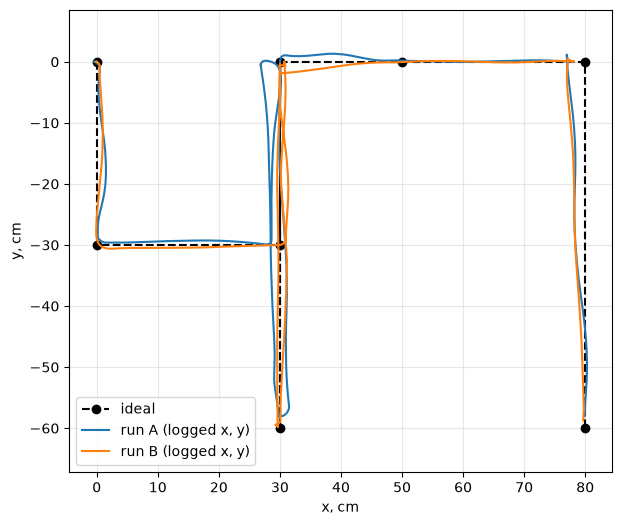

In [3]:
# plot the ideal "47" and the trajectory each robot estimated on board
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(X_ref, Y_ref, "k--o", label="ideal")                      # black dashed line with waypoints
for k, c in (("A", "tab:blue"), ("B", "tab:orange")):
    d = runs[k][runs[k].i > 0]                                    # skip the 10 s at rest (i = 0)
    ax.plot(d.x, d.y, color=c, label=f"run {k} (logged x, y)")    # x, y logged by the robot
# equal axes so the shape is not stretched
ax.axis("equal"); ax.set_xlabel("x, cm"); ax.set_ylabel("y, cm"); ax.legend(); plt.show()

## Step 4.2 — Offline recomputation (4 paths)

Both course methods are recomputed from both logs. $b_0$ is taken from the 10 s at rest with an outlier-rejecting median (Lab 9 method): in run A the robot was turned by hand during seconds 2–6 of that rest (large gyro readings, encoders unchanged), so the on-robot mean $b_0$ of run A is wrong. The median of the quiet samples is not affected.

run A: b0 on robot (mean) = -1.568 deg/s,  robust b0 = +0.078 deg/s
run B: b0 on robot (mean) = +0.168 deg/s,  robust b0 = +0.170 deg/s
run A (odom): max |x, y| difference to the on-robot estimate = 0.00 cm, course 0.00 deg
run B (gyro): max |x, y| difference to the on-robot estimate = 0.00 cm, course 0.00 deg


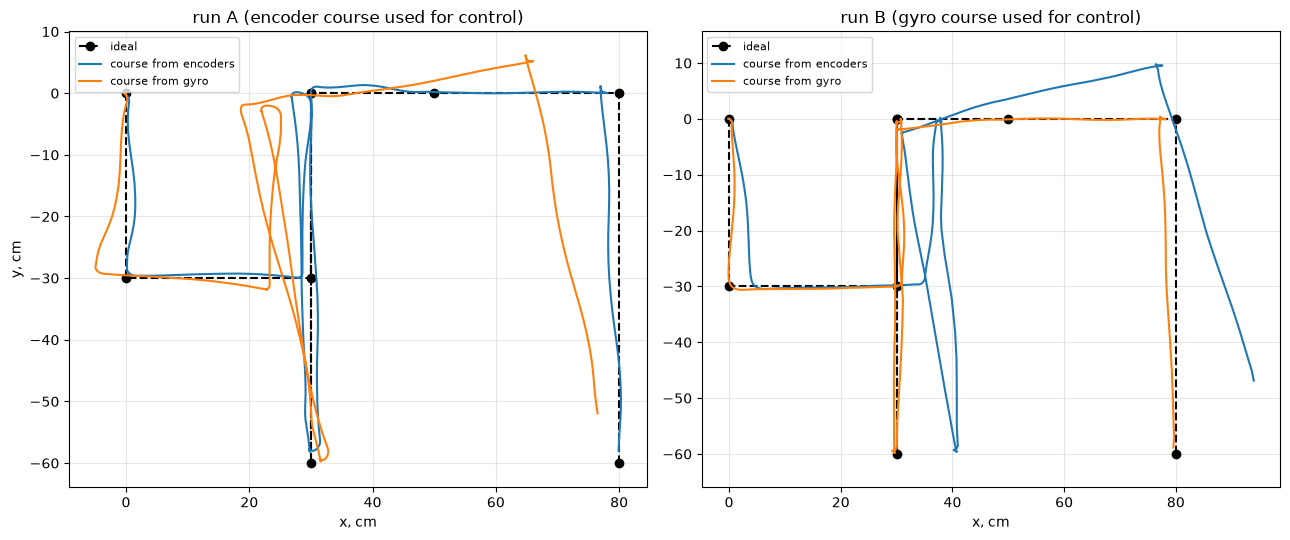

In [4]:
# ---------- gyro bias b0 ----------
# b0 = what the gyro reads while the robot stands still (it should be 0).
# A plain mean is ruined by spikes (run A was turned by hand during the rest),
# so: median -> MAD (typical distance from the median) -> drop samples > 4 MAD away -> median again.
def robust_b0(d):
    x = d.gz[d.i == 0].values / 1000                              # rest samples, mdeg/s -> deg/s
    # median = middle value; MAD * 1.4826 = spread (like a standard deviation, but robust)
    med = np.median(x); mad = 1.4826 * np.median(np.abs(x - med))
    # keep only the quiet samples and take their median
    return np.median(x[np.abs(x - med) <= 4 * mad])

# ---------- rebuild a run offline ----------
# method "odom": course from the wheels, method "gyro": course from the gyro.
# Path (distance) always comes from the wheels.
def recompute(d, method, b0):
    q = d[d.i > 0].reset_index(drop=True)                         # driving rows only, numbered from 0
    # distance travelled = average wheel angle (rad) * wheel radius
    path = (q.theta_r + q.theta_l) * r / 2
    if method == "odom":
        # encoder course: right wheel ahead of left -> robot turned left; divide by B to get the angle
        course = (q.theta_r - q.theta_l) * r / B
    else:
        # time between samples (s); the first step starts at the last rest sample
        dt = np.diff(np.concatenate([[d.t[d.i == 0].iloc[-1]], q.t])) / 1000
        # gyro course: rate (deg/s) - bias, / (1 + s) for the scale error, * dt = degrees per step,
        # * pi/180 = radians, cumsum = add up all steps (integration)
        course = np.cumsum((q.gz / 1000 - b0) / (1 + s) * dt * np.pi / 180)
    # distance moved in each step (difference of the total distance)
    dp = np.diff(np.concatenate([[0], path]))
    # dead reckoning: move each step in the current direction and add up, starting at waypoint 0
    x = X_ref[0] + np.cumsum(dp * np.cos(course)); y = Y_ref[0] + np.cumsum(dp * np.sin(course))
    # result table; dl, dr = wheel angle change per step (used later to find straight driving)
    return pd.DataFrame({"t": q.t, "i": q.i, "path": path, "course": np.asarray(course), "x": x, "y": y,
                         "dl": np.diff(np.concatenate([[0], q.theta_l])), "dr": np.diff(np.concatenate([[0], q.theta_r]))})

# ---------- b0 of both runs ----------
# compare the robot's simple mean with the robust value
b0 = {}
for k, d in runs.items():
    b0[k] = robust_b0(d)
    print(f"run {k}: b0 on robot (mean) = {d.gz[d.i == 0].mean() / 1000:+.3f} deg/s,  robust b0 = {b0[k]:+.3f} deg/s")

# ---------- 4 paths ----------
# every run with both methods: (A, odom), (A, gyro), (B, odom), (B, gyro)
rec = {(k, m): recompute(runs[k], m, b0[k]) for k in runs for m in ("odom", "gyro")}

# ---------- check ----------
# rebuild each run with the method that steered it and the robot's own b0;
# it must give exactly the robot's logged x, y, course (proves the formulas match the robot)
for k, m in (("A", "odom"), ("B", "gyro")):
    q = runs[k][runs[k].i > 0].reset_index(drop=True)
    own = recompute(runs[k], m, runs[k].gz[runs[k].i == 0].mean() / 1000)    # robot's own b0
    print(f"run {k} ({m}): max |x, y| difference to the on-robot estimate = "
          f"{max(np.abs(own.x - q.x).max(), np.abs(own.y - q.y).max()):.2f} cm, course {np.degrees(np.abs(wrap(own.course - q.course)).max()):.2f} deg")

# ---------- plot ----------
# left run A, right run B: ideal, path with encoder course, path with gyro course
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, k in zip(axes, ("A", "B")):
    ax.plot(X_ref, Y_ref, "k--o", label="ideal")
    ax.plot(rec[(k, "odom")].x, rec[(k, "odom")].y, label="course from encoders")
    ax.plot(rec[(k, "gyro")].x, rec[(k, "gyro")].y, label="course from gyro")
    ax.set_title(f"run {k} ({'encoder' if k == 'A' else 'gyro'} course used for control)")
    ax.axis("equal"); ax.set_xlabel("x, cm"); ax.legend(fontsize=8)
axes[0].set_ylabel("y, cm"); plt.tight_layout(); plt.show()

*In each run the method that steered the robot draws a clean "47", because the controller follows its own estimate. The other method shows the same run seen by the second sensor. The two disagree by ≈ 3–4 % of every turn: over the whole run the encoder course turns 439° where the gyro turns 454° (run B), and 268° against 279° (run A). After the 180° turns this puts the second path 10–15 cm off.*

## Step 4.3 — Course

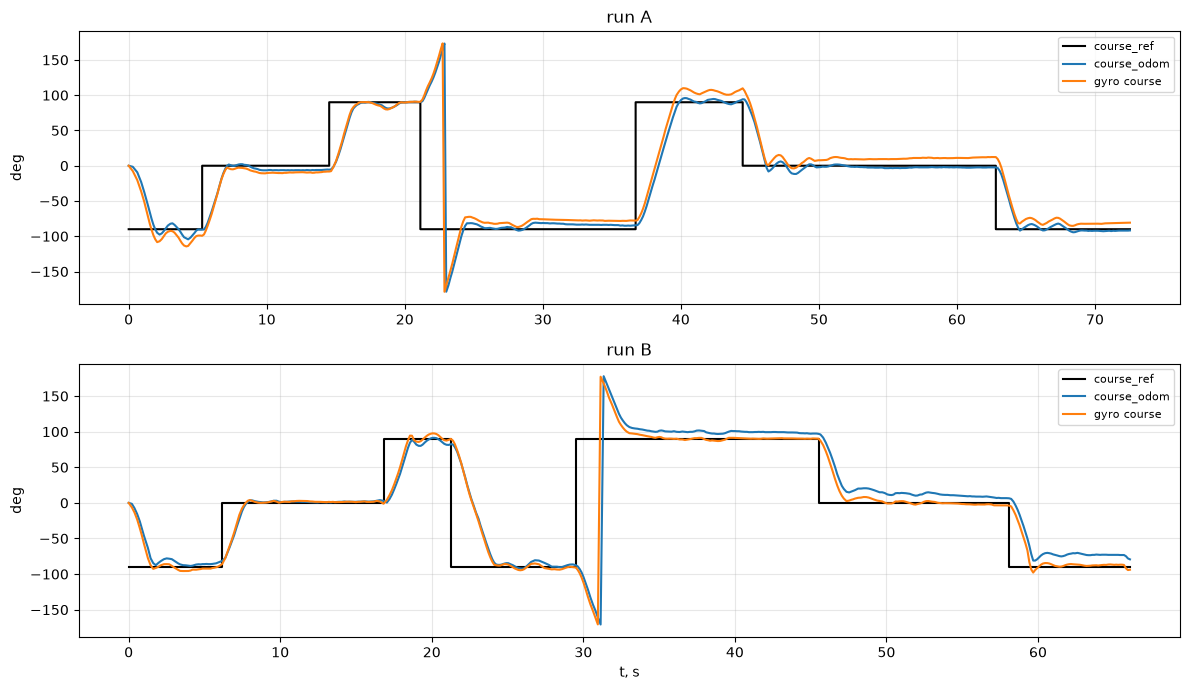

In [5]:
# ---------- course and path per segment ----------
# for every segment i: mean course while driving straight, driven length, end point
def segments(q):
    out = []
    for i in range(1, len(X_ref)):
        seg = q[q.i == i]                                         # all rows of segment i (turn + drive)
        # straight driving = both wheels move forward (in the turn they move in opposite directions)
        drv = seg[(seg.dl > 0) & (seg.dr > 0)]
        out.append(dict(
            # circular mean: average the angles as unit vectors exp(1j*angle), then take the angle back
            # (a plain mean of 179 and -179 deg gives 0 deg, the circular mean gives 180 deg)
            course=np.degrees(np.angle(np.mean(np.exp(1j * drv.course)))) if len(drv) else np.nan,
            # segment length = total distance at the end of segment i - at the end of segment i-1
            path=seg.path.iloc[-1] - (q[q.i == i - 1].path.iloc[-1] if i > 1 else 0),
            # where the segment ended
            end_x=seg.x.iloc[-1], end_y=seg.y.iloc[-1]))
    return pd.DataFrame(out, index=range(1, len(X_ref)))

# seg: each run with the sensor that steered it (A encoders, B gyro) -> used in the table
seg = {k: segments(rec[(k, "odom" if k == "A" else "gyro")]) for k in runs}          # logged estimate of each run
# cross: each run with the other sensor
cross = {k: segments(rec[(k, "gyro" if k == "A" else "odom")]) for k in runs}        # the other sensor

# ---------- plot: course over time ----------
# black steps = ideal course of the current segment; lines = encoder course and gyro course
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=False)
for ax, k in zip(axes, ("A", "B")):
    q_o, q_g = rec[(k, "odom")], rec[(k, "gyro")]
    t = (q_o.t - q_o.t.iloc[0]) / 1000                            # time from the start of driving, s
    ax.step(t, np.degrees(course_ref[q_o.i.values - 1]), "k", where="post", label="course_ref")
    ax.plot(t, np.degrees(wrap(q_o.course)), label="course_odom")
    ax.plot(t, np.degrees(wrap(q_g.course)), label="gyro course")
    ax.set_title(f"run {k}"); ax.set_ylabel("deg"); ax.legend(fontsize=8)
axes[1].set_xlabel("t, s"); plt.tight_layout(); plt.show()

## Step 4.4 / Deliverable 4 — Comparison table

In [6]:
# ---------- course error per segment ----------
# d_course = real course - ideal course, wrapped to -180..180 deg
dA = wrap(np.radians(seg["A"].course) - course_ref); dB = wrap(np.radians(seg["B"].course) - course_ref)

# ---------- comparison table ----------
# per segment: ideal course, real course of A and B, their errors;
# ideal path, real path of A and B, their errors
tab = pd.DataFrame({
    "course_ref, °": np.degrees(course_ref).round(1),
    "course A, °": seg["A"].course.round(1), "course B, °": seg["B"].course.round(1),
    "d_course A, °": np.degrees(dA).round(1), "d_course B, °": np.degrees(dB).round(1),
    "path_ref, cm": path_ref.round(1), "path A, cm": seg["A"].path.round(1), "path B, cm": seg["B"].path.round(1),
    "d_path A, cm": (seg["A"].path - path_ref).round(1), "d_path B, cm": (seg["B"].path - path_ref).round(1)})
tab.index.name = "segment"
# summary row: mean |course error| of each run, total path, total path error (cm and %)
tab.loc["summary"] = ["", "", "", f"mean |·| {np.degrees(np.abs(dA)).mean():.1f}", f"mean |·| {np.degrees(np.abs(dB)).mean():.1f}",
                      round(path_ref.sum(), 1), round(seg['A'].path.sum(), 1), round(seg['B'].path.sum(), 1),
                      f"{(seg['A'].path.sum() - path_ref.sum()):.1f} ({100 * (seg['A'].path.sum() / path_ref.sum() - 1):+.1f} %)",
                      f"{(seg['B'].path.sum() - path_ref.sum()):.1f} ({100 * (seg['B'].path.sum() / path_ref.sum() - 1):+.1f} %)"]
display(tab)

# ---------- final error ----------
# distance from the last estimated point to the last waypoint, and the course error at the end
for k in runs:
    q = rec[(k, "odom" if k == "A" else "gyro")]
    ce = np.degrees(wrap(q.course.iloc[-1] - course_ref[-1]))
    print(f"run {k}: final position error {np.hypot(q.x.iloc[-1] - X_ref[-1], q.y.iloc[-1] - Y_ref[-1]):.1f} cm, final course error {ce:+.1f} deg (own estimate)")

,"course_ref, °","course A, °","course B, °","d_course A, °","d_course B, °","path_ref, cm","path A, cm","path B, cm","d_path A, cm","d_path B, cm"
segment,,,,,,,,,,
1,-90.0,-92.8,-91.6,-2.8,-1.6,30.0,28.5,28.5,-1.5,-1.5
2,0.0,-6.9,0.3,-6.9,0.3,30.0,28.7,30.1,-1.3,0.1
3,90.0,87.6,85.0,-2.4,-5.0,30.0,28.3,30.6,-1.7,0.6
4,-90.0,-85.4,-90.4,4.6,-0.4,60.0,62.4,59.2,2.4,-0.8
5,90.0,91.5,89.9,1.5,-0.1,60.0,57.5,59.2,-2.5,-0.8
6,0.0,2.9,4.4,2.9,4.4,20.0,20.7,18.2,0.7,-1.8
7,0.0,-1.6,-0.3,-1.6,-0.3,30.0,29.6,30.0,-0.4,0.0
8,-90.0,-87.3,-86.6,2.7,3.4,60.0,57.6,58.2,-2.4,-1.8
summary,,,,mean |·| 3.2,mean |·| 1.9,320.0,313.4,314.0,-6.6 (-2.1 %),-6.0 (-1.9 %)


run A: final position error 2.0 cm, final course error -1.8 deg (own estimate)
run B: final position error 1.2 cm, final course error -3.9 deg (own estimate)


*Course and path in the table are the robot's own estimates. A and B hold their own course equally well, so the difference between the methods shows up only when one sensor is checked against the other (next step).*

## Step 4.5 — Error growth

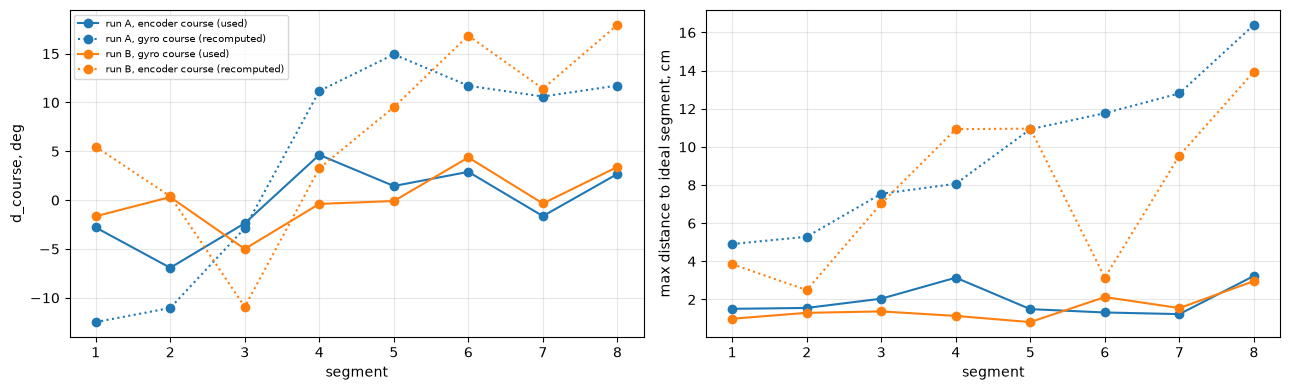

run A: encoder − gyro course at the end of each segment: [  8.5   2.8  -0.3  -6.8 -15.3  -8.  -14.6 -11. ] deg
run B: encoder − gyro course at the end of each segment: [ 5.2  2.  -7.1  3.8  7.2 12.1 10.2 14.6] deg


In [7]:
# ---------- distance to the ideal line ----------
# shortest distance from points (px, py) to ideal segment i (from point a to point b):
# u = where the point projects onto the segment (0 = at a, 1 = at b), clipped to stay on the segment,
# then the distance between the point and that closest point
def seg_dist(px, py, i):
    ax_, ay, bx, by = X_ref[i - 1], Y_ref[i - 1], X_ref[i], Y_ref[i]
    u = np.clip(((px - ax_) * (bx - ax_) + (py - ay) * (by - ay)) / ((bx - ax_) ** 2 + (by - ay) ** 2), 0, 1)
    return np.hypot(px - ax_ - u * (bx - ax_), py - ay - u * (by - ay))

# ---------- error growth plots ----------
# 4 paths: solid = sensor that steered the run (used), dotted = other sensor (recomputed)
# left: course error per segment, right: worst distance from the ideal segment
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
for (k, m), c, ls in ((("A", "odom"), "tab:blue", "-"), (("A", "gyro"), "tab:blue", ":"), (("B", "gyro"), "tab:orange", "-"), (("B", "odom"), "tab:orange", ":")):
    q = rec[(k, m)]; sg = segments(q)
    dc = np.degrees(wrap(np.radians(sg.course) - course_ref))     # course error per segment, deg
    # largest distance from the ideal line inside each segment
    dist = [seg_dist(q.x[q.i == i].values, q.y[q.i == i].values, i).max() for i in range(1, len(X_ref))]
    lab = f"run {k}, {'encoder' if m == 'odom' else 'gyro'} course" + (" (used)" if (k, m) in (("A", "odom"), ("B", "gyro")) else " (recomputed)")
    a1.plot(sg.index, dc, ls, color=c, marker="o", label=lab); a2.plot(sg.index, dist, ls, color=c, marker="o", label=lab)
a1.set_xlabel("segment"); a1.set_ylabel("d_course, deg"); a1.legend(fontsize=7)
a2.set_xlabel("segment"); a2.set_ylabel("max distance to ideal segment, cm")
plt.tight_layout(); plt.show()

# ---------- where the error builds up ----------
# encoder course - gyro course at the end of each segment;
# it jumps after the turns, so the turns cause most of the disagreement
for k in runs:
    o, g = rec[(k, "odom")], rec[(k, "gyro")]
    gap = np.degrees(o.course - g.course)
    print(f"run {k}: encoder − gyro course at the end of each segment: {np.round(gap.groupby(o.i).last().values, 1)} deg")

*The course used for control stays within 1–3 cm of the ideal segments in both runs. Recomputed with the other sensor, the error grows to 14–16 cm, and it grows mostly in steps after the turns (most after the 180° turns of segments 3–5).*

## Analysis

**Course and path.** In its own estimate, run B is closer to the ideal course (mean |d_course| 1.9° against 3.2°). The path errors are almost the same (−1.9 % and −2.1 %), because both runs measure distance with the same wheel encoders, so only the course differs. Both runs stop ≈ 1.5–2 cm short of each waypoint (acceptance radius 2 cm), which explains most of the negative d_path.

**Dominant error.** Most of the net gap between the encoder course and the gyro course builds up during the turns (run A: −11° in turns against −0.3° on straights; run B: +21° against −8°), ≈ 3–4 % of the turned angle. On the straights the two sensors wobble against each other but largely cancel. That points to the encoder course (wheel slip in the in-place turns and the unmeasured track width B) and to the gyro scale factor, not to bias. The bias was small and well calibrated (0.17 deg/s in run B, < 1° over the run). In run A it was wrongly measured on the robot (the robot was turned by hand during the 10 s at rest), which does not affect run A's control but would have ruined a gyro-based run. The scale factor s = −6.2 % from Lab 9 was measured with fast spins, where the wheels slip more; with the slow turns here the corrected gyro turns ≈ 3.5 % more than the encoders, so s was probably over-estimated by about that much. The gyro never reached its 286.7 deg/s limit (turn power ≤ 20 %).

**Combining both.** The gyro is reliable over a single turn (no slip, no B), while the encoders do not drift when the robot stands still. A complementary filter uses the gyro increment for fast changes and pulls slowly towards the encoder course: `course = 0.01 * course_odom + 0.99 * (course + gyro_inc)` (Lab 11). Re-measuring s with slow turns would remove most of the remaining gap.